### 1.setup

In [16]:

from dotenv import load_dotenv
import os

In [17]:
load_dotenv()  # Load environment variables from .env file


True

In [18]:
from langchain_groq import ChatGroq

In [19]:
llm=ChatGroq(model="openai/gpt-oss-20b")


In [13]:
res=llm.invoke("hello")
res.content

'Hello! 👋 How can I help you today?'

#### 2.State - Global State to pass the data between the all nodes

In [14]:
from pydantic import BaseModel


In [15]:
class Userstate(BaseModel):
    name: str=""
    age: int=0
    email: str=""
 
state=Userstate(name="prabesh")  


In [16]:
state

Userstate(name='prabesh', age=0, email='')

#### 2.1) Building the graph using the Langgraph

In [17]:
from langgraph.graph import StateGraph , END ,START 
from pydantic import BaseModel

In [18]:
class Mystate(BaseModel):
    messages: str=""
    


In [19]:
def greet(state:Mystate):
    "I am the geet node ..."
    state.messages="hello! Good morning"
    return state



In [20]:
graph =StateGraph(Mystate)
graph.add_node("greet", greet)

In [21]:
graph.add_edge(START, "greet")
graph.add_edge("greet", END)

In [22]:
final_graph=graph.compile()

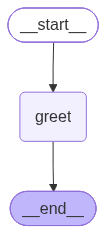

In [23]:
final_graph

In [24]:
res=final_graph.invoke({"messages":"hello"})

In [25]:
res

{'messages': 'hello! Good morning'}

#### 2.2) Multi node graph

In [26]:
from random import randint


In [27]:
class ReviewState(BaseModel):
    text: str=""
    score: int=0
    comments: str=""

In [28]:
def score(state:ReviewState)->ReviewState:
    state.score=randint(1,10)
    return state

In [29]:
def commenter(state:ReviewState)->ReviewState:
    if state.score>5:
        state.comments="well done! that's a nice score"
    else:
        state.comments="that's a bad score"
    return state

In [30]:
graph=StateGraph(ReviewState)


In [31]:
graph.add_node("score", score)
graph.add_node("commenter", commenter)


In [32]:
graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)

In [33]:
final_graph=graph.compile()

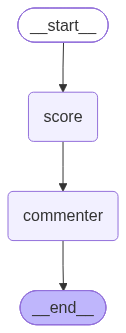

In [34]:
final_graph

In [35]:
res=final_graph.invoke({})

In [36]:
res

{'text': '', 'score': 4, 'comments': "that's a bad score"}

#### 3 `add_messages` reducer - for chat history

In [37]:
from langgraph.graph.message import add_messages

In [38]:
from typing import Annotated
from langgraph.graph import StateGraph , END ,START 
from pydantic import BaseModel

In [39]:
def custom_reducer(existing:list,new:list):
    return ["hello"]

In [40]:
class ChatState(BaseModel):
    messages: Annotated[list, add_messages]=[]

In [41]:
def chat_bot(state:ChatState)->ChatState:
    state.messages=llm.invoke(state.messages)
    return state

In [42]:
graph=StateGraph(ChatState)

In [43]:
graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

In [44]:
final_graph=graph.compile()

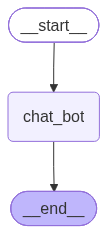

In [45]:
final_graph

In [46]:
res=final_graph.invoke({"messages":[{"role":"user","content":"hello"}]})

#### 4. Routing - Core component of Langgraph

In [47]:
from langgraph.graph import StateGraph , END ,START
from pydantic import BaseModel
from typing import Literal

In [48]:
class TicketState(BaseModel):
    issue: str=""
    category: str=""
    response:str=""

In [49]:
def classify(state:TicketState)->TicketState:
    issue=state.issue.lower()
    if "payment" in issue or "billing" in issue:
        state.category="Billing"
    elif "refund" in issue or "cancel" in issue:
        state.category="refund"
    else:
        state.category="status"
        
    return state

In [50]:
def handle_billing(state:TicketState)->TicketState:
    state.response="Please provide your billing details"
    return state

def handle_refund(state:TicketState)->TicketState:
    state.response="Please provide your refund details"
    return state

def handle_status(state:TicketState)->TicketState:
    state.response="Please provide your status"
    return state

In [51]:
# remember this is not the node but the router logic that will be used to route the state to the appropriate node based on the category
def router_logic(state:TicketState)->Literal["billing","refund","status"]:
    return state.category
    

In [52]:
graph=StateGraph(TicketState)

In [53]:

graph.add_node("classify", classify)
graph.add_node("billing", handle_billing)
graph.add_node("refund", handle_refund)
graph.add_node("status", handle_status)


In [54]:
graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", router_logic)
graph.add_edge("billing", END)
graph.add_edge("refund", END)
graph.add_edge("status", END)


In [55]:
final_graph=graph.compile()

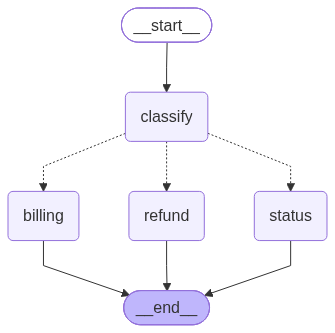

In [56]:
final_graph

In [57]:
res=final_graph.invoke({"issue":"i need my refund"})

In [58]:
res

{'issue': 'i need my refund',
 'category': 'refund',
 'response': 'Please provide your refund details'}

#### 5. Memory - Checkpointer

In [42]:
from langgraph.graph import StateGraph , END ,START
from pydantic import BaseModel
from langgraph.checkpoint.memory import InMemorySaver

In [60]:
class ChatState(BaseModel):
    messages: Annotated[list, add_messages]
    
    

In [61]:
def chat_bot(state:ChatState)->ChatState:
    state.messages=llm.invoke(state.messages)
    return state

In [62]:
graph=StateGraph(ChatState)

In [63]:
graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

In [64]:
memory=InMemorySaver()

In [65]:
final_graph=graph.compile(checkpointer=memory)

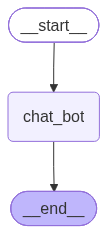

In [66]:
final_graph

In [67]:
res=final_graph.invoke({"messages":[{"role":"user","content":"hello i am prabesh"}]}
                       ,
                    {"configurable":{"thread_id":"1"}}
                       )

In [68]:
res

{'messages': [HumanMessage(content='hello i am prabesh', additional_kwargs={}, response_metadata={}, id='f7c9fc1c-133b-4755-b9ee-c23512ce5904'),
  AIMessage(content='Hello, Prabesh! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hello i am prabesh". We should respond politely, maybe ask how we can help. The user hasn\'t provided a specific request. We can ask what they need.'}, response_metadata={'token_usage': {'completion_tokens': 63, 'prompt_tokens': 77, 'total_tokens': 140, 'completion_time': 0.064460487, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.004248953, 'prompt_tokens_details': None, 'queue_time': 0.329208322, 'total_time': 0.06870944}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d6de37e6be', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13aa1-562f-71d1-8376-b0f0724baa67-0', tool_calls=[], invalid_tool_calls=[], usage_metadat

In [69]:
ans=res["messages"][-1].content

In [70]:
ans

'Hello, Prabesh! 👋 How can I help you today?'

In [71]:
res=final_graph.invoke({"messages":[{"role":"user","content":"hello what is my name"}]}
                       ,
                    {"configurable":{"thread_id":"1"}}
                       )

In [72]:
ans=res["messages"][-1].content

In [73]:
ans

'You’re Prabesh! If you’d like to share more or ask anything else, just let me know.'

In [74]:
%pip install langgraph-checkpoint-sqlite

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

In [44]:
connection=sqlite3.connect("db.sqlite3", check_same_thread=False) 

In [45]:
sql_memory=SqliteSaver(connection)
sql_memory.setup()

In [46]:
sqlite_graph=graph.compile(checkpointer=sql_memory)

In [47]:
res=sqlite_graph.invoke({"messages":{"role":"user","content":"hello i am prabesh"}},{"configurable":{"thread_id":"sql1"}})

ValueError: "AgentState" object has no field "messsages"

In [ ]:
ans=res["messages"][-1].content
print(ans)

Hello Prabesh! 👋 How can I assist you today?


#### 6. Agents and Tools - ToolNodes

In [ ]:
from langchain.tools import tool

In [ ]:
@tool
def weather_tool(city:str)->str:
    """This is a weather tool that takes a city name and returns the weather in that city
    Args:
        city (str): The name of the city for which to get the weather.
    """
    data={
        "kathmandu":"38",
        "pokhara":"25",
        "biratnagar":"30"
    }
    return data.get(city.lower(), "City not found")

In [ ]:
@tool
def calculate(expression:str)->str:
    """This is a calculator tool that takes a mathematical expression and returns the result
    Args:
        expression (str): The mathematical expression to evaluate.
    """
    try:
        result=eval(expression)
        return str(result)
    except Exception as e:
        return str(e)

In [48]:
from typing import Annotated
from pydantic import BaseModel
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph , END ,START
from langgraph.graph.message import add_messages
##new
from langgraph.prebuilt import tools_condition , ToolNode

In [64]:
class AgentState(BaseModel):
    messages:Annotated[list,add_messages]
    


# class ChatState(BaseModel):
#     messages: Annotated[list, add_messages]
    
tools=[weather_tool,calculate]
    

In [65]:
llm_with_tools=llm.bind_tools(tools)

In [66]:
def chat_bot(state:AgentState)->AgentState:
    res=llm_with_tools.invoke(state.messages)
    state.messages=[res]
    return state

In [67]:
tool_node=ToolNode(tools)

In [68]:
graph=StateGraph(AgentState)

In [69]:
graph.add_node("chat_bot",chat_bot)
graph.add_node("tools",tool_node)



In [70]:

graph.add_edge(START, "chat_bot")

graph.add_conditional_edges("chat_bot", tools_condition)

graph.add_edge("tools", "chat_bot")


In [71]:
final_graph=graph.compile(checkpointer=sql_memory)

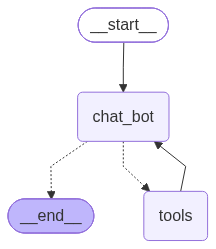

In [72]:
final_graph

In [73]:
res=final_graph.invoke({"messages":
    {"role":"user","content":"what is the temperature in kathmnadu"}},
                       {"configurable":{"thread_id":"sql2"}})

In [74]:
ans=res["messages"][-1].content

In [77]:
print(ans)

The current temperature in **Kathmandu** is **38 °C**.


In [78]:
for msg in res["messages"]:
    msg.pretty_print()

================================ Human Message =================================

what is the temperature in kathmnadu
================================ Human Message =================================

what is the temperature in kathmnadu
================================ Human Message =================================

what is the temperature in kathmnadu
================================ Human Message =================================

what is the temperature in kathmnadu
================================ Human Message =================================

what is the temperature in kathmnadu
================================== Ai Message ==================================
Tool Calls:
  weather_tool (fc_1ced1816-f560-4bb4-b5aa-038ce7f70b6e)
 Call ID: fc_1ced1816-f560-4bb4-b5aa-038ce7f70b6e
  Args:
    city: Kathmandu
================================= Tool Message =================================
Name: weather_tool

38
================================== Ai Message ===========================

#### 7) Human-in-the-Loop

In [119]:
from pydantic import BaseModel
from langgraph.graph import StateGraph,START,END
from langgraph.types import interrupt , Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

In [120]:
class PurchaseState(BaseModel):
    item:str=""
    price:int=0
    confirmed:bool=False
    status:str=""
    
    
    

In [121]:
def show_orders(state:PurchaseState)-> PurchaseState:
    print(f"Order Summary Product : {state.item} and price : {state.price}")
    return state

    

In [122]:
def user_confirmation(state:PurchaseState)->PurchaseState:
    response=interrupt(
        {
            "question":f"confirm your purchase for {state.item} and price is {state.price} "
        }
    )
    
    state.confirmed=response.lower() =="yes"
    return state

In [123]:
def order_cancel(state:PurchaseState)->PurchaseState:
    print("we have canceled your order. Thanks")
    return state

In [124]:
def order_confirm(state:PurchaseState)->PurchaseState:
    print("you successfully placed your order...")
    return state

In [125]:
def router(state:PurchaseState)->Literal["cancel","confirm"]:
    if state.confirmed:
        return "confirm"
    return "cancel"

In [126]:
graph=StateGraph(PurchaseState)
graph.add_node("show_orders",show_orders)
graph.add_node("user_confirmation",user_confirmation)
graph.add_node("cancel",order_cancel)
graph.add_node("confirm",order_confirm)


In [127]:
graph.add_edge(START,"show_orders")
graph.add_edge("show_orders","user_confirmation")
graph.add_conditional_edges("user_confirmation",router)
graph.add_edge("cancel",END)
graph.add_edge("confirm",END)


In [128]:
final_graph=graph.compile(checkpointer=sql_memory)


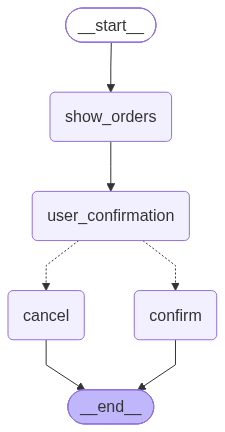

In [129]:
final_graph

In [130]:
res=final_graph.invoke(
    {
        "item":"samsung s23","price":12000
    },
    {
        "configurable":{"thread_id":"asd10"}
    }
)

Order Summary Product : samsung s23 and price : 12000


In [131]:
print(res["__interrupt__"][0].value["question"])

confirm your purchase for samsung s23 and price is 12000 


In [132]:

from langgraph.types import Command

res = final_graph.invoke(
    Command(resume="yes"),
    config={"configurable": {"thread_id": "asd10"}}
)

print(res)



you successfully placed your order...
{'item': 'samsung s23', 'price': 12000, 'confirmed': True, 'status': ''}
